# Artwork Artist Classification — Transfer Learning with EfficientNet

**Computer Vision · Image Classification · PyTorch Lightning · Weights & Biases**

## Актуальность

Автоматическая атрибуция произведений искусства по изображению — задача компьютерного зрения, полезная для организации цифровых коллекций, поиска похожих произведений и анализа визуальных особенностей авторского стиля. Картины различаются композицией, техникой, размером и цветовой палитрой, поэтому перенос признаков из моделей, обученных на фотографиях, требует экспериментальной проверки.

## Постановка проблемы

По изображению картины необходимо определить её автора. В работе рассматриваются две постановки: классификация наиболее представленных художников и классификация расширенного набора из 50 авторов. Дополнительно исследуется влияние дисбаланса классов.

## Методы

- **Transfer learning:** EfficientNet с различной глубиной разморозки слоёв.
- **Аугментации:** преобразования изображений для повышения устойчивости модели.
- **Работа с дисбалансом:** взвешенная кросс-энтропия.
- **Инструменты:** PyTorch, torchvision, PyTorch Lightning, Weights & Biases.

## Метрики и оценка

- **Macro-F1** — основная метрика, позволяющая оценивать качество по авторам без доминирования крупных классов.
- **Cross-entropy loss** — контроль динамики обучения и валидации.
- **F1 для частых и редких классов** — анализ влияния дисбаланса.

Ниже приведены проведённые эксперименты, их сохранённые результаты и визуализации.


In [ ]:
!pip install -q pytorch-lightning wandb

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from pathlib import Path
from shutil import copyfile
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

import torch
from torch import nn
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import efficientnet_b6
from torch.utils.data import DataLoader, RandomSampler

import wandb
from torchmetrics.classification import MulticlassF1Score
from pytorch_lightning import LightningModule, Trainer
from pytorch_lightning.loggers import WandbLogger
from pytorch_lightning.callbacks import Callback, ModelCheckpoint

In [ ]:
sns.set(style='darkgrid', palette='Set2')
wandb.login()

<IPython.core.display.Javascript object>

wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


True

## 1. Задача: атрибуция произведений искусства

Цель — классифицировать картины по автору на основе визуальных признаков с помощью transfer learning.

### Данные

Набор изображений произведений искусства и метаданные художников: [исходный датасет](https://disk.yandex.ru/d/_BUueJa4RVXplQ). Изображения организованы по авторам и разделены на обучающую и тестовую выборки.

In [ ]:
# Запишите путь до архива.
zip_path = '.../artworks.zip'
# Замените пробелы в пути, чтобы следующая bash-команда работала корректно.
zip_path_bash = str(zip_path).replace(' ', '\ ')
# Разархивируйте файлы.
!unzip $zip_path_bash -d .
# Укажите путь до данных.
data_path = Path('./artworks')

Данные представлены каталогами `images/train`, `images/test` и таблицей `artists.csv` с характеристиками авторов.

In [ ]:
sorted((data_path / 'images' / 'train').iterdir())

Рассмотрим структуру каталогов с изображениями отдельных художников.

In [ ]:
sorted((data_path / 'images' / 'train' / 'Albrecht_Durer').iterdir())

### Примеры изображений

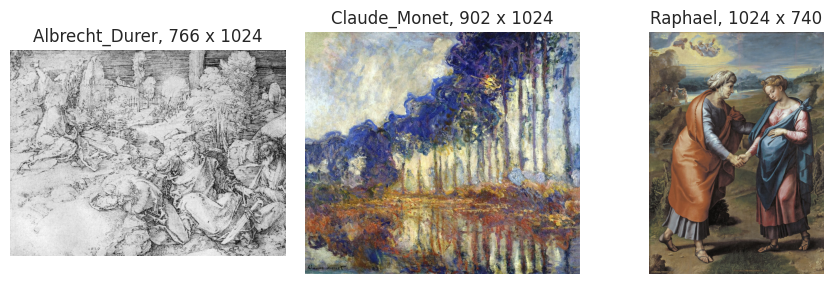

In [ ]:
images_paths = [
    data_path / 'images' / 'train' / 'Albrecht_Durer' / 'Albrecht_Durer_310.jpg',
    data_path / 'images' / 'train' / 'Claude_Monet' / 'Claude_Monet_007.jpg',
    data_path / 'images' / 'train' / 'Raphael' / 'Raphael_100.jpg'
]
plt.figure(figsize=(9, 3))
for i, image_path in enumerate(images_paths):
    author = image_path.parent.name
    plt.subplot(1, 3, i + 1)
    image = plt.imread(image_path)
    plt.imshow(image)
    plt.title(f'{author}, {image.shape[0]} x {image.shape[1]}')
    plt.axis("off")
plt.tight_layout()

### Состав и распределение классов

In [ ]:
artists_df = pd.read_csv(data_path / 'artists.csv')
artists_df.head()

,name,years,genre,nationality,bio,wikipedia,paintings
0,Amedeo Modigliani,1884 - 1920,Expressionism,Italian,Amedeo Clemente Modigliani (Italian pronunciat...,http://en.wikipedia.org/wiki/Amedeo_Modigliani,193
1,Vasiliy Kandinskiy,1866 - 1944,"Expressionism,Abstractionism",Russian,Wassily Wassilyevich Kandinsky (Russian: Васи́...,http://en.wikipedia.org/wiki/Wassily_Kandinsky,88
2,Diego Rivera,1886 - 1957,"Social Realism,Muralism",Mexican,Diego María de la Concepción Juan Nepomuceno E...,http://en.wikipedia.org/wiki/Diego_Rivera,70
3,Claude Monet,1840 - 1926,Impressionism,French,Oscar-Claude Monet (; French: [klod mɔnɛ]; 14 ...,http://en.wikipedia.org/wiki/Claude_Monet,73
4,Rene Magritte,1898 - 1967,"Surrealism,Impressionism",Belgian,René François Ghislain Magritte (French: [ʁəne...,http://en.wikipedia.org/wiki/René_Magritte,194


Количество произведений по авторам существенно различается. Сначала исследуем классификацию наиболее представленных художников, затем расширим задачу до всех классов.

Для первого эксперимента выбраны авторы, представленные не менее чем 200 работами.

In [ ]:
freq_artists = artists_df['name'][artists_df['paintings'] >= 200].values
N_CLASSES = len(freq_artists)
freq_artists, N_CLASSES

(array(['Vincent van Gogh', 'Pablo Picasso', 'Pierre-Auguste Renoir',
        'Francisco Goya', 'Albrecht Dürer', 'Alfred Sisley',
        'Marc Chagall', 'Edgar Degas', 'Rembrandt', 'Titian',
        'Paul Gauguin'], dtype=object),
 11)

Названия авторов сопоставляются с именами директорий.

In [ ]:
freq_artists_dirs = []
for artist in freq_artists:
    if artist == 'Albrecht Dürer':
        artist_dir = 'Albrecht_Durer'
    else:
        artist_dir = '_'.join(artist.split())
    freq_artists_dirs.append(artist_dir)

Формируем подвыборку изображений для выбранных авторов в формате `ImageFolder`.

In [ ]:
images_selected_path = Path('images_selected')
images_selected_path.mkdir(exist_ok=True)
for mode in ['train', 'test']:
    (images_selected_path / mode).mkdir(exist_ok=True)
    for artist_dir in tqdm(freq_artists_dirs):
        (images_selected_path / mode / artist_dir).mkdir(exist_ok=True)
        for file_path in (data_path / 'images' / mode / artist_dir).iterdir():
            copyfile(file_path, images_selected_path / mode / artist_dir / file_path.name)

  0%|          | 0/11 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

### Базовая предобработка

Используем изменение размера, центральное кадрирование и нормализацию изображений.

In [ ]:
input_size = 224
simple_transform = transforms.Compose([
    transforms.Resize(input_size),      # Меняем размер картинки, наименьшая из сторон становится размера input_size
    transforms.CenterCrop(input_size),  # Вырезаем квадрат из центра изображения
    transforms.ToTensor(),
    transforms.Normalize(               # Нормализуем картинки в соотвествии со статистикой из ImageNet
        [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

Формируем наборы данных для обучения и оценки.

In [ ]:
train_dataset = ImageFolder(
    root=images_selected_path / 'train',
    transform=simple_transform,
)
test_dataset = ImageFolder(
    root=images_selected_path / 'test',
    transform=simple_transform,
)
len(train_dataset), len(test_dataset)

(3004, 1295)

Настраиваем загрузчики данных.

In [ ]:
batch_size = 8
training_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=RandomSampler(
        train_dataset,
        replacement=True
    ),
    num_workers=2
)
validation_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    num_workers=2
)

### 2. Transfer learning с EfficientNet

Для экспериментов выбрана EfficientNet: архитектура сочетает высокое качество распознавания изображений с эффективным использованием параметров. Сравниваем разные стратегии заморозки слоёв предобученной сети.

Поскольку художественные изображения отличаются от фотографий из стандартных датасетов, исследуем дообучение части и всех слоёв модели.

Реализация модели на PyTorch Lightning.

In [ ]:
class FineTunedEfficientNet(LightningModule):
    def __init__(self, to_freeze, n_classes=N_CLASSES, lr=0.001):
        '''Инициализация модели
        * to_freeze -- сколько слоев хотим заморозить, максимум: 9.
        * n_classes -- кол-во классов
        * lr -- learning rate для оптимизатора'''

        super().__init__()
        self.n_classes = n_classes
        self.metric = MulticlassF1Score(num_classes=n_classes, average='macro')
        self.criterion = nn.CrossEntropyLoss()
        self.lr = lr
        self.save_hyperparameters()

        # списки для сохранения предсказаний и меток
        self.test_y_pred, self.test_y_true = [], []
        self.val_y_pred, self.val_y_true = [], []
        self.train_y_pred, self.train_y_true = [], []

        # зададим модель
        self.model = efficientnet_b6(weights='IMAGENET1K_V1')
        # изменим слой классификатора
        self.model.classifier[1] = nn.Linear(2304, n_classes)
        for i in range(to_freeze): # заморозим to_freeze первых слоев
            for param in self.model.features[i].parameters():
                param.requires_grad = False
        for param in self.model.classifier.parameters(): # разморозим классификатор
            param.requires_grad = True

    def configure_optimizers(self):
        return torch.optim.Adam(self.model.parameters(), lr=self.lr)

    def forward(self, x):
        return self.model(x)

    def __step(self, batch, list_preds, list_gt, name=None, log_loss=True):
        ''' Один шаг работы с batch.
        * list_preds -- список для сохранения предсказаний
        * list_gt -- список для сохранения истинных меток
        * name -- `train` или `val`
        * log_loss -- логировать ли лосс '''

        x, y = batch
        list_gt.append(y)
        logits = self(x)
        preds = torch.argmax(logits, dim=1)
        list_preds.append(preds)
        loss = self.criterion(logits, y)
        if log_loss:
            self.log(name+'_loss', loss) # логируем лосс
        return preds, loss

    def training_step(self, batch, batch_idx):
        '''1 шаг обучения по батчу'''
        _, loss = self.__step(batch, self.train_y_pred, self.train_y_true, name='train')
        return loss

    def validation_step(self, batch, batch_idx):
        '''1 шаг валидации по батчу'''
        preds, _ = self.__step(batch, self.val_y_pred, self.val_y_true, name='val')
        # возвращаем предсказания, чтобы использовать их в callback
        return preds

    def test_step(self, batch, batch_idx):
        '''1 шаг тестирования по батчу'''
        self.__step(batch, self.test_y_pred, self.test_y_true, log_loss=False)

    def __end_epoch(self, list_preds, list_gt, name):
        '''Логирование метрики, очищение сохраненных значений'''
        all_preds = torch.concatenate(list_preds)
        all_gt = torch.concatenate(list_gt)
        self.log(name+'_F1_score', self.metric(all_preds, all_gt))
        list_preds.clear()
        list_gt.clear()

    def on_train_epoch_end(self):
        self.__end_epoch(self.train_y_pred, self.train_y_true, 'train')

    def on_validation_epoch_end(self):
        self.__end_epoch(self.val_y_pred, self.val_y_true, 'val')

    def on_test_epoch_start(self):
        '''Очищение списков перед началом тестирования'''
        self.test_y_pred.clear()
        self.test_y_true.clear()

In [ ]:
class LogPredictionsCallback(Callback):
    def on_validation_batch_end(
        self, trainer, pl_module, outputs, batch, batch_idx):
        '''Вызывается после валидационного батча.
        `outputs` приходит из `LightningModule.validation_step`,
        что в данном случае соответствует предсказаниям модели'''

        # Будем логировать предсказания для 8 картинок
        if batch_idx == 0:
            n = 8
            x, y = batch
            images = [img for img in x[:n]]
            captions = [f'Ground Truth: {y_i} - Prediction: {y_pred}' for y_i, y_pred in zip(y[:n], outputs[:n])]

            # логируем картинки
            wandb_logger.log_image(key='sample_images', images=images, caption=captions)

log_predictions_callback = LogPredictionsCallback()

#### Эксперимент A: замороженный feature extractor

In [ ]:
frozen_extractor_model = FineTunedEfficientNet(to_freeze=9)
checkpoint_callback = ModelCheckpoint(monitor='val_F1_score', mode='max')
wandb_logger = WandbLogger(project='Artworks', log_model='all')
trainer = Trainer(logger=wandb_logger,
                  callbacks=[log_predictions_callback, checkpoint_callback],
                  max_epochs=10)
trainer.fit(frozen_extractor_model, training_loader, validation_loader)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name      | Type              | Params
------------------------------------------------
0 | metric    | MulticlassF1Score | 0     
1 | criterion | CrossEntropyLoss  | 0     
2 | model     | EfficientNet      | 40.8 M
------------------------------------------------
25.4 K    Trainable params
40.7 M    Non-trainable params
40.8 M    Total params
163.044   Total estimated model params size (MB)


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (5 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


In [ ]:
wandb.finish()

epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇████
train_F1_score,▁▅▆▇█▇████
train_loss,▇█▅▄▅▇▄▃█▇▆▄▅▄▂▃▃▆▅▅▄▄▄▁▅▂▃▄▃▆▄▅▂▅▃▂▅▅▂▃
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇████
val_F1_score,▁▄▆▆▇▇▇▇██
val_loss,█▅▄▃▂▂▂▁▁▁
epoch,9
train_F1_score,0.65866
train_loss,0.92658
trainer/global_step,3759
val_F1_score,0.60435


#### Эксперимент B: частичная разморозка EfficientNet

Сравниваем число обучаемых параметров и качество модели при заморозке первых шести блоков.

In [ ]:
semi_frozen_model = FineTunedEfficientNet(to_freeze=6)
wandb.init(project='Artworks')
wandb_logger = WandbLogger(project='Artworks', log_model='all')
trainer = Trainer(logger=wandb_logger,
                  callbacks=[log_predictions_callback, checkpoint_callback],
                  max_epochs=10)
trainer.fit(semi_frozen_model, training_loader, validation_loader)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
/usr/local/lib/python3.10/dist-packages/pytorch_lightning/loggers/wandb.py:389: There is a wandb run already in progress and newly created instances of `WandbLogger` will reuse this run. If this is not desired, call `wandb.finish()` before instantiating `WandbLogger`.
/usr/local/lib/python3.10/dist-packages/pytorch_lightning/callbacks/model_checkpoint.py:630: Checkpoint directory ./Artworks/utdxmyh4/checkpoints exists and is not empty.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name      | Type              | Params
------------------------------------------------
0 | metric   

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


In [ ]:
wandb.finish()

epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇████
train_F1_score,▁▅▆▇▇▇████
train_loss,█▆▄█▃▄▃▃▃▄▂▃▆▃▃▃▁▃▃▃▂▂▁▁▄▁▁▁▂▁▁▁▃▂▆▁▁▁▁▁
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇███
val_F1_score,▁▅█▇████▇▇
val_loss,█▃▁▂▁▁▂▂▂▃
epoch,9
train_F1_score,0.94346
train_loss,0.01428
trainer/global_step,3759
val_F1_score,0.79926


#### Эксперимент C: дообучение всех слоёв

In [ ]:
unfrozen_model = FineTunedEfficientNet(to_freeze=0)
wandb.init(project='Artworks')
wandb_logger = WandbLogger(project='Artworks', log_model='all')
trainer = Trainer(logger=wandb_logger,
                  callbacks=[log_predictions_callback,checkpoint_callback],
                  max_epochs=10)
trainer.fit(unfrozen_model, training_loader, validation_loader)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name      | Type              | Params
------------------------------------------------
0 | metric    | MulticlassF1Score | 0     
1 | criterion | CrossEntropyLoss  | 0     
2 | model     | EfficientNet      | 40.8 M
------------------------------------------------
40.8 M    Trainable params
0         Non-trainable params
40.8 M    Total params
163.044   Total estimated model params size (MB)


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


In [ ]:
wandb.finish()

epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇████
train_F1_score,▁▄▆▆▇▇████
train_loss,█▅▃▅▅▂▃▃▅▃▄▂▃▄▄▁▂▄▄▃▁▅▁▁▁▃▄▁▄▁▃▃▅▂▂▁▄▁▁▁
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇███
val_F1_score,▁▂▆▅▄█▇▇▇▅
val_loss,▇█▁▄▅▁▃▃▂▅
epoch,9
train_F1_score,0.91613
train_loss,0.11872
trainer/global_step,3759
val_F1_score,0.71024


### Сравнение стратегий fine-tuning

Основная метрика — **macro-F1**: она учитывает precision и recall и придаёт одинаковый вес каждому классу независимо от числа изображений. Это особенно важно при неравномерном распределении картин по авторам.

* Метрика F1 хороша тем, что она уравновешивает Precision и Recall. Благодаря методу усреднения macro мы уделяем внимание каждому классу одинаково, вне зависимости от того, как широко он представлен в данных.

* Лучшая метрика у данной сети за 10 эпох &mdash; у модели с 6 замороженными слоями. Вероятнее всего полностью размороженная модель не успела обучиться, ведь у нее на 8 миллионов больше обучаемых параметров. В целом, метрика на текущей стадии все еще нестабильна, и может быть такое, что качества моделей `semi-frozen` и `unfrozen` статистически неотличимы.

### 3. Аугментация изображений

Для повышения устойчивости модели применяем геометрические преобразования, сохраняя характерные особенности художественного стиля и цветовой палитры. Аугментации должны быть такими, чтобы не поменялся стиль автора. Во многом стиль зависит от выбранной цветовой палитры, яркости и контрастности изображений. Поэтому будем  в основном использовать аугментации которые изменяют размер и форму, а цвета изменим минимально.

In [ ]:
input_size = 224
complex_transform_unnorm = transforms.Compose([
    transforms.RandomResizedCrop(size=input_size, scale=(0.7, 1), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.1),
    transforms.ToTensor(),
])
complex_transform = transforms.Compose([
    complex_transform_unnorm,
    transforms.Normalize(  # Нормализуем картинки в соотвествии со статистикой из ImageNet
        [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

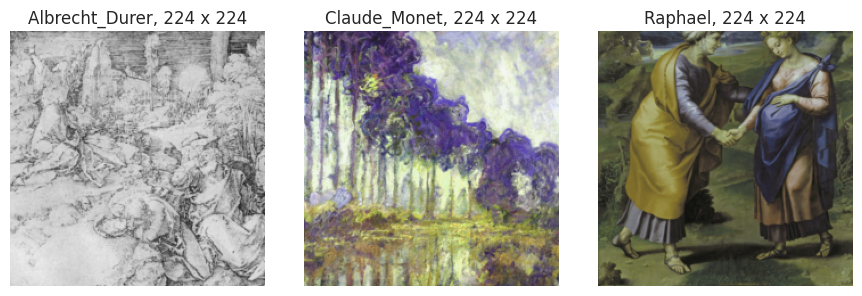

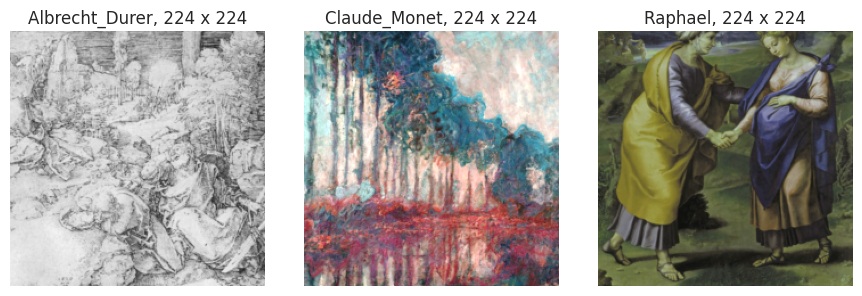

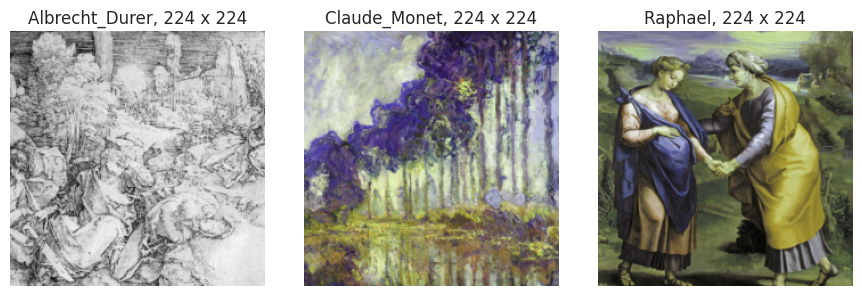

In [ ]:
for _ in range(3):
    plt.figure(figsize=(9, 3))
    for i, image_path in enumerate(images_paths):
        author = image_path.parent.name
        plt.subplot(1, 3, i + 1)
        image = Image.open(image_path)
        trans_image = complex_transform_unnorm(image).moveaxis(0, 2)
        plt.imshow(trans_image)
        plt.title(f'{author}, {trans_image.shape[0]} x {trans_image.shape[1]}' )
        plt.axis("off")
    plt.tight_layout()

In [ ]:
train_dataset = ImageFolder(
    root=images_selected_path / 'train',
    transform=complex_transform,
)

training_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=RandomSampler(
        train_dataset,
        replacement=True
    )
)

Обучение EfficientNet с частично размороженными слоями на аугментированных данных.

In [ ]:
semi_frozen_model = FineTunedEfficientNet(to_freeze=6)
wandb.init(project='Artworks')
wandb_logger = WandbLogger(project='Artworks', log_model='all')
trainer = Trainer(logger=wandb_logger,
                  callbacks=[log_predictions_callback, checkpoint_callback],
                  max_epochs=10)
trainer.fit(semi_frozen_model, training_loader, validation_loader)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name      | Type              | Params
------------------------------------------------
0 | metric    | MulticlassF1Score | 0     
1 | criterion | CrossEntropyLoss  | 0     
2 | model     | EfficientNet      | 40.8 M
------------------------------------------------
32.9 M    Trainable params
7.9 M     Non-trainable params
40.8 M    Total params
163.044   Total estimated model params size (MB)


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.10/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=1` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (5 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


In [ ]:
wandb.finish()

epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇████
train_F1_score,▁▄▆▇▇▇████
train_loss,█▄▅▆▅▅▃▂▂▃▆▃▃▄▂▁▂▁▃▁▁▃▅▁▁▁▁▁▁▂▁▂▃▂▁▁▁▁▁▂
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇███
val_F1_score,▁▅▆▆██▇▇██
val_loss,█▄▂▃▁▁▂▂▂▁
epoch,9
train_F1_score,0.91288
train_loss,0.22615
trainer/global_step,3759
val_F1_score,0.84117


### Эффект аугментаций

Удалось поднять метрику с `0.79926` до `0.84117`. Метрика на обучении при этом была стабильно меньше и ближе к валидации, эффект переобучения меньше. Аугментации позволили расширить обучающую выборку для модели, что привело к улучшению качества.

In [ ]:
train_dataset = ImageFolder(
    root=data_path / 'images' / 'train',
    transform=complex_transform,
)
test_dataset = ImageFolder(
    root=data_path / 'images' / 'test',
    transform=simple_transform,
)
training_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=RandomSampler(
        train_dataset,
        replacement=True
    ),
    num_workers=2
)
validation_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    num_workers=2
)
len(train_dataset.classes)

50

Обучение модели на расширенном наборе авторов.

In [ ]:
full_model = FineTunedEfficientNet(to_freeze=0, n_classes=50)
wandb.init(project='Artworks')
wandb_logger = WandbLogger(project='Artworks', log_model='all')
trainer = Trainer(logger=wandb_logger,
                  callbacks=[log_predictions_callback, checkpoint_callback],
                  max_epochs=10)
trainer.fit(full_model, training_loader, validation_loader)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
/usr/local/lib/python3.10/dist-packages/pytorch_lightning/loggers/wandb.py:389: There is a wandb run already in progress and newly created instances of `WandbLogger` will reuse this run. If this is not desired, call `wandb.finish()` before instantiating `WandbLogger`.
/usr/local/lib/python3.10/dist-packages/pytorch_lightning/callbacks/model_checkpoint.py:630: Checkpoint directory ./Artworks/utdxmyh4/checkpoints exists and is not empty.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name      | Type              | Params
------------------------------------------------
0 | metric   

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


На расширенном наборе классов итоговое качество классификации ниже.

In [ ]:
def test_freq_rare_classes(model, trainer):
    '''Сравнивает F1 Score для широко и редко - представленных классов
    * model -- модель для тестирования
    * trainer -- трейнер, которым она обучалась'''

    # тестируем модель - для этого в model должен быть test_step()
    trainer.test(model, dataloaders=validation_loader)
    y_pred = np.concatenate([t.cpu().numpy() for t in model.test_y_pred])
    y_true = np.concatenate([t.cpu().numpy() for t in model.test_y_true])

    # freq_mask - маска для таргета, freq_classes - индексы частых
    freq_classes_mask = np.isin(train_dataset.classes, freq_artists_dirs)
    freq_classes = np.arange(50)[freq_classes_mask]
    rare_classes = np.arange(50)[~freq_classes_mask]
    freq_mask = np.isin(y_true, freq_classes)

    # вычисляем F1 Score
    freq = f1_score(y_pred[freq_mask], y_true[freq_mask],
                    labels=freq_classes, average='macro')
    rare = f1_score(y_pred[~freq_mask], y_true[~freq_mask],
                    labels=rare_classes, average='macro')
    print("F1 Score для широко представленных классов:\t", freq)
    print("F1 Score для редко представленных классов:\t", rare)

Оценим качество отдельно для часто и редко представленных авторов.

In [ ]:
test_freq_rare_classes(full_model, trainer)

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

F1 Score для широко представленных классов:	 0.7667157908938467
F1 Score для редко представленных классов:	 0.5039944651058444


Для редких авторов наблюдается более низкое качество классификации.

In [ ]:
wandb.finish()

epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇████
train_F1_score,▁▃▄▅▆▆▇▇██
train_loss,█▆▅▅▅▄▃▆▅▃▅▃▃▄▅▇▂▁▅▃▄▃▃▁▁▃▂▁▁▂▂▂▃▃▁▄▁▁▃▃
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
val_F1_score,▁▄▅▅▇▇▇▇██
val_loss,█▂▃▅▁▂▁▃▁▁
epoch,9
train_F1_score,0.70287
train_loss,1.07952
trainer/global_step,7359
val_F1_score,0.5223


### 4. Работа с дисбалансом классов

Для снижения влияния дисбаланса используем взвешенную `CrossEntropyLoss`: классы с меньшим числом изображений получают больший вес.

Веса классов рассчитываются обратно пропорционально количеству картин; порядок классов согласован с метками в датасете.

In [ ]:
full_model_weighted_CEL = FineTunedEfficientNet(to_freeze=0, n_classes=50)
weight = 1 / artists_df.sort_values('name')['paintings'].values
weight = torch.from_numpy(weight).to(torch.float32)
full_model_weighted_CEL.criterion = nn.CrossEntropyLoss(weight=weight)
wandb_logger = WandbLogger(project='Artworks', log_model='all')

Обучение модели со взвешенной функцией потерь.

In [ ]:
wandb.init(project='Artworks')
wandb_logger = WandbLogger(project='Artworks', log_model='all')
trainer = Trainer(logger=wandb_logger,
                  callbacks=[log_predictions_callback, checkpoint_callback],
                  max_epochs=10)
trainer.fit(full_model_weighted_CEL, training_loader, validation_loader)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
/usr/local/lib/python3.10/dist-packages/pytorch_lightning/loggers/wandb.py:389: There is a wandb run already in progress and newly created instances of `WandbLogger` will reuse this run. If this is not desired, call `wandb.finish()` before instantiating `WandbLogger`.
/usr/local/lib/python3.10/dist-packages/pytorch_lightning/callbacks/model_checkpoint.py:630: Checkpoint directory ./Artworks/utdxmyh4/checkpoints exists and is not empty.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name      | Type              | Params
------------------------------------------------
0 | metric   

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


Сравнение macro-F1 на полном наборе и отдельно для групп авторов.

In [ ]:
test_freq_rare_classes(full_model_weighted_CEL, trainer)

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

F1 Score для широко представленных классов:	 0.6401884967027781
F1 Score для редко представленных классов:	 0.5419832573330259


In [ ]:
wandb.finish()

epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇████
train_F1_score,▁▃▃▅▅▆▆▇██
train_loss,▆█▅▄▅▃▄▃▄▅▃▃▃▂▃▅▃▃▃▃▃▁▄▃▃▁▂▁▂▂▃▃▂▄▂▁▃▂▂▄
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
val_F1_score,▁▃▄▅▆▅▆▆▆█
val_loss,▁▁▁▁▁█▁▁▁▁
epoch,9
train_F1_score,0.59276
train_loss,0.68216
trainer/global_step,7359
val_F1_score,0.49794


### Влияние весов классов

Метрики между широко и плохо представленными классами сблизились, и для редко представленных классов метрика увеличилась с `0.504` до `0.542`.

### 5. Сравнение экспериментов и динамики обучения

Визуализация функций потерь и macro-F1 по эпохам для проведённых запусков в Weights & Biases.

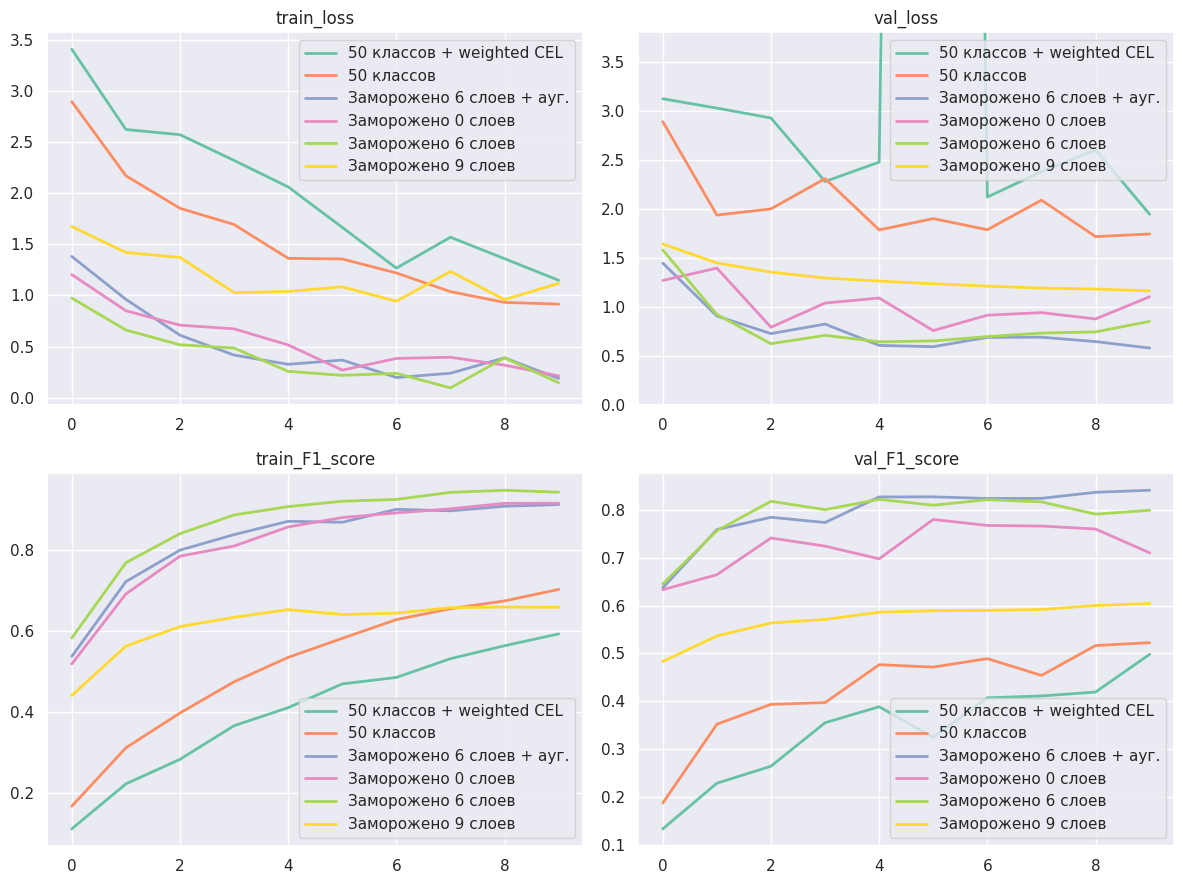

In [ ]:
runs = wandb.Api().runs("Artworks")
subplot_names = np.array([['train_loss', 'val_loss'],
                          ['train_F1_score', 'val_F1_score']])

fig, axs = plt.subplots(2, 2, figsize=(12, 9))
lw = 2
for i, run in enumerate(runs):
    df = run.history().groupby('epoch').mean(numeric_only=True)
    for k in range(2):
        for m in range(2):
            axs[k, m].set_title(subplot_names[k, m])
            axs[k, m].plot(df[subplot_names[k, m]], lw=lw, label=run.name)
            axs[k, m].legend()
    axs[0, 1].set_ylim((0, 3.8))
plt.tight_layout()

## 6. Итоги

Мы попробовали fine-tuning для задачи классификации картин художников. Картины довольно сильно отличаются от естественных изображений, и лучшим способом дообучения оказалось зазморозить только 6 из 9 слоев модели, оставив большинство параметров обучаемыми. На широко представленных классах модель неплохо обучилась, достигнув значения метрики F1 `0.79` на тесте. При добавлении аугментации во время обучения метрика возросла до `0.84`. На всех классах модель показала более слабый результат и метрика достигла значения `0.52`. Дело в том, что на малопредставленных классах модель плохо выучилась. При изменении весов классов для вычисления лосса общая метрика понизилась, но метрика для малопредставленных классов возросла с `0.504` до `0.542`.